# Dengue (evento 210) — extracción y preparación de datos SIVIGILA

Este notebook une los archivos anuales de SIVIGILA, los limpia y genera la **serie mensual de casos por municipio de ocurrencia**, que es la base para el canal endémico y los modelos.

**Qué necesitas:** una carpeta en Google Drive con los archivos `Datos_AAAA_210.xlsx` (uno por año, sin renombrar).

**Qué produce (en la carpeta de salida):**
- `casos_limpios.parquet`: un registro por caso, limpio.
- `serie_mensual_municipios.csv`: casos por municipio y mes, con los meses sin casos en 0.
- `ranking_municipios.csv`: tabla de apoyo para elegir municipios.
- `perfil_social.csv`: distribución de casos por estrato, régimen y área.

In [ ]:
!pip install -q python-calamine

In [ ]:
import glob, os, re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # fuera de Colab

CARPETA = '/content/drive/MyDrive/Datos'    # archivos Datos_AAAA_210.xlsx
SALIDA  = '/content/drive/MyDrive/Datos/dengue/procesado'
os.makedirs(SALIDA, exist_ok=True)

MUNICIPIOS = {               # código DANE (dpto+mpio) -> nombre
    '50001': 'Villavicencio',
    '73001': 'Ibagué',
    '23001': 'Montería',
}
FECHA_MIN, FECHA_MAX = '2007-01-01', '2025-12-31'   # rango de inicio de síntomas (usar todos los años disponibles)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Lectura de los archivos anuales


Solo se leen las columnas necesarias y los nombres se normalizan a mayúsculas, porque pueden variar entre años.

In [ ]:
COLUMNAS = ['CONSECUTIVE', 'COD_EVE', 'FEC_NOT', 'SEMANA', 'ANO', 'COD_PRE', 'COD_SUB',
            'EDAD', 'UNI_MED', 'SEXO', 'COD_PAIS_O', 'COD_DPTO_O', 'COD_MUN_O', 'AREA', 'TIP_SS', 'ESTRATO',
            'INI_SIN', 'TIP_CAS', 'AJUSTE', 'PAC_HOS',
            'DEPARTAMENTO_OCURRENCIA', 'MUNICIPIO_OCURRENCIA']

def leer_archivo(ruta):
    usar = lambda c: str(c).strip().upper() in COLUMNAS
    if ruta.lower().endswith('.csv'):
        df = pd.read_csv(ruta, dtype=str, usecols=usar, encoding='latin-1', sep=None, engine='python')
    else:
        try:
            df = pd.read_excel(ruta, dtype=str, usecols=usar, engine='calamine')
        except Exception:
            df = pd.read_excel(ruta, dtype=str, usecols=usar)
    df.columns = [str(c).strip().upper() for c in df.columns]
    df['ARCHIVO'] = os.path.basename(ruta)
    return df

archivos = sorted(glob.glob(f'{CARPETA}/Datos_*_210.*'))
anios_arch = [re.search(r'Datos_(\d{4})', os.path.basename(a)).group(1) for a in archivos]
assert archivos, f'No hay archivos Datos_AAAA_210 en {CARPETA}'
assert len(set(anios_arch)) == len(anios_arch), f'Hay años repetidos (p. ej. .xlsx y .csv del mismo año): {anios_arch}'

cache = f'{SALIDA}/cache_sivigila.parquet'
crudo = pd.read_parquet(cache) if os.path.exists(cache) else None
if crudo is None or set(crudo['ARCHIVO']) != {os.path.basename(a) for a in archivos}:
    print(f'{len(archivos)} archivos encontrados')
    partes = []
    for a in archivos:
        partes.append(leer_archivo(a))
        print(f'  {os.path.basename(a)}: {len(partes[-1]):,} registros')
    crudo = pd.concat(partes, ignore_index=True)
    crudo.to_parquet(cache, index=False)

faltan = set(COLUMNAS) - set(crudo.columns)
print(f'Total: {len(crudo):,} registros | columnas ausentes: {faltan or "ninguna"}')
OBLIGATORIAS = {'COD_EVE', 'COD_DPTO_O', 'COD_MUN_O', 'INI_SIN', 'FEC_NOT', 'TIP_CAS', 'AJUSTE', 'ANO'}
assert not (OBLIGATORIAS & faltan), f'Faltan columnas obligatorias: {OBLIGATORIAS & faltan}'
print(crudo.groupby('ARCHIVO').size().to_string())  # revisar que ningún año falte o venga casi vacío

for c in faltan:  # opcionales ausentes: se crean vacías
    crudo[c] = np.nan

19 archivos encontrados
  Datos_2007_210.xlsx: 35,074 registros
  Datos_2008_210.xlsx: 32,793 registros
  Datos_2009_210.xlsx: 45,345 registros
  Datos_2010_210.xlsx: 147,224 registros
  Datos_2011_210.xlsx: 29,386 registros
  Datos_2012_210.xlsx: 52,467 registros
  Datos_2013_210.xlsx: 122,441 registros
  Datos_2014_210.xlsx: 105,356 registros
  Datos_2015_210.xlsx: 95,023 registros
  Datos_2016_210.xlsx: 100,117 registros
  Datos_2017_210.xlsx: 25,048 registros
  Datos_2018_210.xlsx: 43,652 registros
  Datos_2019_210.xlsx: 123,641 registros
  Datos_2020_210.xlsx: 76,419 registros
  Datos_2021_210.xlsx: 49,325 registros
  Datos_2022_210.xlsx: 65,691 registros
  Datos_2023_210.xlsx: 126,411 registros
  Datos_2024_210.xlsx: 309,627 registros
  Datos_2025_210.xlsx: 120,564 registros
Total: 1,705,604 registros | columnas ausentes: ninguna
ARCHIVO
Datos_2007_210.xlsx     35074
Datos_2008_210.xlsx     32793
Datos_2009_210.xlsx     45345
Datos_2010_210.xlsx    147224
Datos_2011_210.xlsx     

## 3. Limpieza
Decisiones principales (deben quedar justificadas en el informe):

- **Fecha de inicio de síntomas (`INI_SIN`)** como fecha del caso, no la de notificación. El formato viene como `3/05/2020 12:00:00 a. m.`: si se corta la fecha por posición se pierde cerca del 30% de los registros, por eso se separa por espacio.
- **Los años se asignan por `INI_SIN`**, no por la columna `ANO`: cada archivo anual trae casos con síntomas del año anterior y del siguiente.
- **Estado final del caso:** se toma el `AJUSTE` cuando confirma (3 = laboratorio, 5 = nexo) y si no, la clasificación inicial `TIP_CAS`. Se excluyen descartados (6) y errores de digitación (D).
- **Municipio de ocurrencia** (`COD_DPTO_O` + `COD_MUN_O`): donde ocurrió la infección, que es donde aplica el clima. Los casos ocurridos en el exterior (país ≠ 170, códigos `01xxx` como "EXTERIOR_VENEZUELA") se excluyen.
- Si algún año trae los códigos como número (`3.0`, `1.0`), se limpia el `.0` antes de completar con ceros.
- **Archivos con `INI_SIN` corrupto:** en el archivo de 2013 la fecha de síntomas no corresponde a la notificación (48% de los casos aparecen notificados *antes* de enfermar, contra 0% en los demás años). Para esos archivos la fecha se imputa como `FEC_NOT − mediana del retraso` de los demás años y se marca en `fecha_imputada`.

In [ ]:
def a_fecha(serie):
    s = serie.astype(str).str.strip().str.split().str[0]
    f = pd.to_datetime(s, format='%d/%m/%Y', errors='coerce')
    for fmt in ['%Y-%m-%d', '%d-%m-%Y', '%d/%m/%y']:
        resto = f.isna()
        f[resto] = pd.to_datetime(s[resto], format=fmt, errors='coerce')
    serial = f.isna() & s.str.fullmatch(r'\d{5}(\.0)?')   # fecha como número de serie de Excel
    f[serial] = pd.to_datetime(s[serial].astype(float), unit='D', origin='1899-12-30')
    return f

df = crudo.copy()
for c in df.columns:
    df[c] = (df[c].astype('string').str.replace('\xa0', ' ').str.strip()
                  .str.replace(r'^(\d+)\.0$', r'\1', regex=True)
                  .replace('', pd.NA))

df['fecha_sintomas'] = a_fecha(df['INI_SIN'])
df['fecha_notif']    = a_fecha(df['FEC_NOT'])

dpto = df['COD_DPTO_O'].str.zfill(2)
mpio = df['COD_MUN_O'].str.zfill(3)
df['cod_mun'] = mpio.where(mpio.str.len().eq(5).fillna(False), dpto + mpio)
pais = df['COD_PAIS_O'].fillna('170').str.zfill(3)

ajuste = df['AJUSTE'].fillna('0').str.upper()
df['estado'] = df['TIP_CAS'].where(~ajuste.isin(['3', '5']), ajuste)
df['estado_nombre'] = df['estado'].map({'2': 'Probable', '3': 'Conf. laboratorio', '5': 'Conf. nexo'})
df['confirmado'] = df['estado'].isin(['3', '5']).astype(int)
df['dias_notif'] = (df['fecha_notif'] - df['fecha_sintomas']).dt.days

# archivos donde INI_SIN no es confiable: >5% de casos con síntomas después de la notificación
pct_neg = (df['dias_notif'] < 0).groupby(df['ARCHIVO']).mean()
corruptos = pct_neg[pct_neg > 0.05].index
retraso = int(df.loc[~df['ARCHIVO'].isin(corruptos) & (df['dias_notif'] >= 0), 'dias_notif'].median())
df['fecha_imputada'] = df['ARCHIVO'].isin(corruptos)
df.loc[df['fecha_imputada'], 'fecha_sintomas'] = df['fecha_notif'] - pd.Timedelta(days=retraso)
df.loc[df['fecha_imputada'], 'dias_notif'] = retraso
print(f'Fecha imputada (FEC_NOT − {retraso} días) en: {list(corruptos) or "ninguno"}')

n0 = len(df)
filtros = {
    'evento distinto de 210':     df['COD_EVE'].ne('210'),
    'descartado / error (6, D)':  ajuste.isin(['6', 'D']),
    'tipo de caso no reconocido': ~df['estado'].isin(['2', '3', '5']),
    'ocurrido en el exterior':    pais.ne('170') | df['cod_mun'].str.startswith('01'),
    'sin municipio de ocurrencia': df['cod_mun'].isna(),
    'fecha de síntomas inválida': df['fecha_sintomas'].isna(),
    'síntomas después de notif.': df['dias_notif'] < 0,
    'fuera del rango de fechas':  ~df['fecha_sintomas'].between(FECHA_MIN, FECHA_MAX),
}
excluir = pd.Series(False, index=df.index)
for motivo, m in filtros.items():
    m = m.fillna(False).astype(bool)
    nuevos = m & ~excluir
    print(f'{motivo:30s}: {nuevos.sum():>8,}')
    excluir |= m
df = df[~excluir]

claves = [c for c in ['CONSECUTIVE', 'COD_PRE', 'COD_SUB', 'INI_SIN', 'EDAD', 'SEXO', 'cod_mun'] if c in df]
dup = df.duplicated(subset=claves).sum()
df = df.drop_duplicates(subset=claves)
print(f'{"duplicados":30s}: {dup:>8,}')
print(f'Quedan {len(df):,} de {n0:,} registros ({len(df)/n0:.1%})')

Fecha imputada (FEC_NOT − 4 días) en: ['Datos_2013_210.xlsx']
evento distinto de 210        :        0
descartado / error (6, D)     :        0
tipo de caso no reconocido    :        0
ocurrido en el exterior       :    3,467
sin municipio de ocurrencia   :        0
fecha de síntomas inválida    :      104
síntomas después de notif.    :        7
fuera del rango de fechas     :    1,137
duplicados                    :        0
Quedan 1,700,889 de 1,705,604 registros (99.7%)


## 4. Diagnóstico de calidad por archivo
Sirve para la sección 2 del informe. La columna `% síntomas otro año` muestra cuántos casos del archivo tienen inicio de síntomas fuera de su año. El **último mes de la serie suele quedar incompleto**, porque esos casos se notifican en el archivo del año siguiente.

In [ ]:
df['anio_sintomas'] = df['fecha_sintomas'].dt.year
diag = (df.assign(otro_anio=df['anio_sintomas'].astype(str) != df['ANO'])
          .groupby('ARCHIVO')
          .agg(casos=('cod_mun', 'size'),
               pct_confirmados=('confirmado', 'mean'),
               pct_sintomas_otro_anio=('otro_anio', 'mean'),
               mediana_dias_a_notif=('dias_notif', 'median'),
               pct_notif_mas_60d=('dias_notif', lambda x: (x > 60).mean())))
diag.style.format({'casos': '{:,}', 'pct_confirmados': '{:.1%}', 'pct_sintomas_otro_anio': '{:.1%}',
                   'pct_notif_mas_60d': '{:.1%}'})

,casos,pct_confirmados,pct_sintomas_otro_anio,mediana_dias_a_notif,pct_notif_mas_60d
ARCHIVO,,,,,
Datos_2007_210.xlsx,"34,804",48.1%,0.6%,3.000000,0.2%
Datos_2008_210.xlsx,"32,790",51.1%,1.3%,3.000000,0.5%
Datos_2009_210.xlsx,"45,310",56.1%,1.1%,3.000000,0.2%
Datos_2010_210.xlsx,"147,005",31.4%,0.1%,3.000000,0.2%
Datos_2011_210.xlsx,"29,321",43.5%,0.0%,3.000000,0.3%
Datos_2012_210.xlsx,"52,394",50.9%,0.0%,4.000000,1.0%
Datos_2013_210.xlsx,"122,299",50.7%,0.8%,4.000000,0.0%
Datos_2014_210.xlsx,"105,170",49.0%,2.0%,4.000000,0.8%
Datos_2015_210.xlsx,"94,960",40.3%,0.9%,4.000000,1.2%


## 5. Serie mensual por municipio
Se arma la grilla completa municipio × mes y se rellena con 0 donde no hubo casos. Sin este paso, los meses sin casos desaparecen y los rezagos y el canal endémico quedan mal calculados.

In [ ]:
df['mes'] = df['fecha_sintomas'].dt.to_period('M').dt.to_timestamp()
meses = pd.date_range(FECHA_MIN, FECHA_MAX, freq='MS')

conteo = df.groupby(['cod_mun', 'mes']).agg(casos=('cod_mun', 'size'), confirmados=('confirmado', 'sum'))
grilla = pd.MultiIndex.from_product([sorted(df['cod_mun'].unique()), meses], names=['cod_mun', 'mes'])
serie = conteo.reindex(grilla, fill_value=0).reset_index()

nombres = (df.dropna(subset=['MUNICIPIO_OCURRENCIA'])
             .groupby('cod_mun')[['DEPARTAMENTO_OCURRENCIA', 'MUNICIPIO_OCURRENCIA']]
             .agg(lambda x: x.mode().iat[0]))
serie = serie.merge(nombres, on='cod_mun', how='left')
print(f'{serie.cod_mun.nunique():,} municipios × {len(meses)} meses = {len(serie):,} filas')

1,115 municipios × 228 meses = 254,220 filas


## 6. Ranking para elegir municipios
Un municipio sirve para el canal endémico mensual si tiene **casos suficientes todos los años** y **pocos meses en cero**. `pct_meses_<5` es la proporción de meses con menos de 5 casos: si es alta, el umbral queda inestable.

In [ ]:
anios = serie.assign(anio=serie['mes'].dt.year).groupby(['cod_mun', 'anio'])['casos'].sum().unstack()
ranking = (serie.groupby('cod_mun')
                .agg(municipio=('MUNICIPIO_OCURRENCIA', 'first'),
                     departamento=('DEPARTAMENTO_OCURRENCIA', 'first'),
                     casos_total=('casos', 'sum'),
                     media_mensual=('casos', 'mean'),
                     pct_meses_cero=('casos', lambda x: (x == 0).mean()),
                     pct_meses_menor5=('casos', lambda x: (x < 5).mean())))
ranking['anios_con_casos'] = (anios > 0).sum(axis=1)
ranking['min_casos_anio'] = anios.min(axis=1)
ranking = ranking.sort_values('casos_total', ascending=False)
ranking['elegido'] = ranking.index.isin(MUNICIPIOS)

ranking.head(30).style.format({'casos_total': '{:,}', 'media_mensual': '{:.1f}',
                               'pct_meses_cero': '{:.0%}', 'pct_meses_menor5': '{:.0%}'})

,municipio,departamento,casos_total,media_mensual,pct_meses_cero,pct_meses_menor5,anios_con_casos,min_casos_anio,elegido
cod_mun,,,,,,,,,
76001,CALI,VALLE,"160,693",704.8,0%,2%,19,149,False
73001,IBAGUE,TOLIMA,"57,295",251.3,0%,0%,19,317,True
05001,MEDELLIN,ANTIOQUIA,"56,872",249.4,4%,5%,19,17,False
68001,BUCARAMANGA,SANTANDER,"54,471",238.9,0%,0%,19,267,False
50001,VILLAVICENCIO,META,"53,370",234.1,0%,0%,19,306,True
54001,CUCUTA,NORTE SANTANDER,"49,709",218.0,0%,0%,19,417,False
08001,BARRANQUILLA,ATLANTICO,"47,532",208.5,0%,0%,19,641,False
41001,NEIVA,HUILA,"36,359",159.5,0%,0%,19,383,False
13001,CARTAGENA,BOLIVAR,"35,422",155.4,0%,9%,19,55,False


## 7. Series de los municipios elegidos

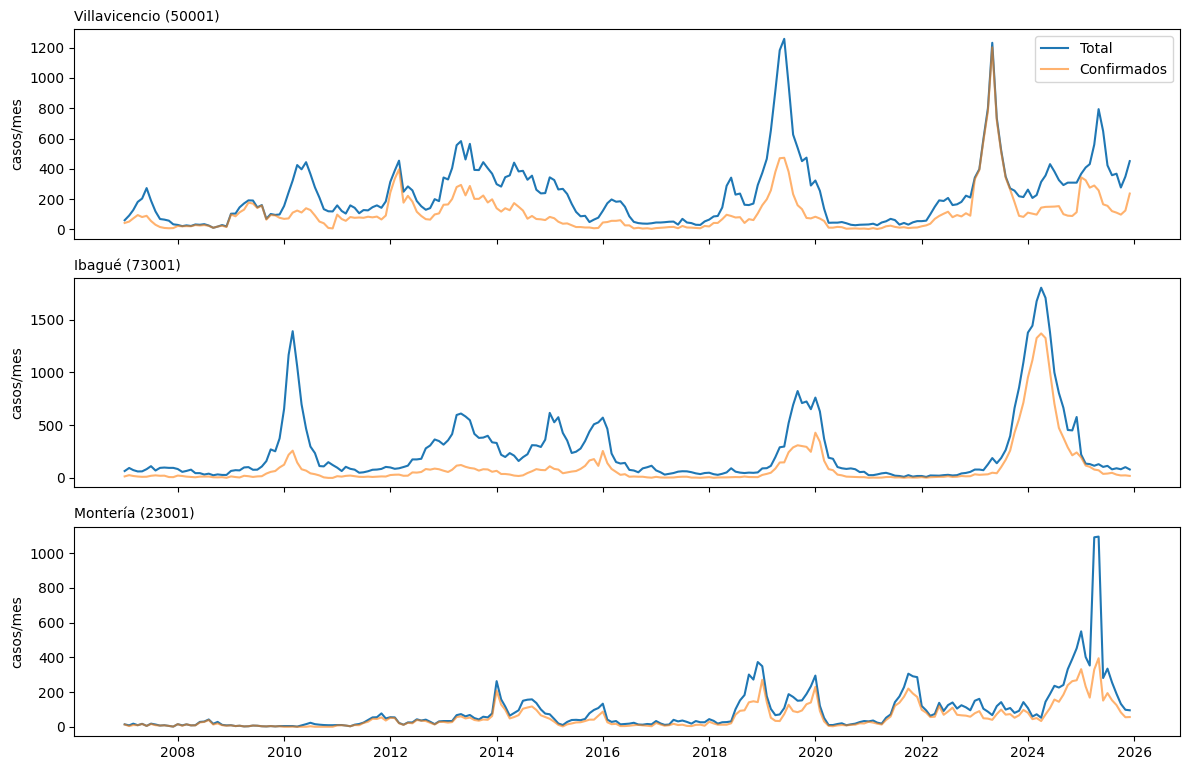

In [ ]:
sel = serie[serie['cod_mun'].isin(MUNICIPIOS)]
fig, axes = plt.subplots(len(MUNICIPIOS), 1, figsize=(12, 2.6 * len(MUNICIPIOS)), sharex=True)
for ax, (cod, nombre) in zip(np.atleast_1d(axes), MUNICIPIOS.items()):
    s = sel[sel['cod_mun'] == cod]
    ax.plot(s['mes'], s['casos'], label='Total')
    ax.plot(s['mes'], s['confirmados'], alpha=.6, label='Confirmados')
    ax.set_title(f'{nombre} ({cod})', loc='left', fontsize=10)
    ax.set_ylabel('casos/mes')
np.atleast_1d(axes)[0].legend()
plt.tight_layout(); plt.show()

## 8. Perfil social de los casos
Distribución de los casos por **estrato**, **régimen de salud** y **área**.

El **estrato** solo existe en los archivos recientes, así que su tabla cubre únicamente esos años; régimen y área cubren toda la serie.

Esto describe *quiénes* se enferman, **no el riesgo** por sector. Para hablar de riesgo hace falta el denominador (población por estrato o régimen) o un indicador municipal como el **NBI o el IPM del DANE (censo 2018)**. Con 3 o 4 municipios, la comparación entre ellos es descriptiva, no inferencial.

In [ ]:
mapas = {
    'TIP_SS':  {'C': 'Contributivo', 'S': 'Subsidiado', 'P': 'Excepción', 'E': 'Especial',
                'N': 'No asegurado', 'I': 'Indeterminado'},
    'AREA':    {'1': 'Cabecera', '2': 'Centro poblado', '3': 'Rural disperso'},
}
d = df[df['cod_mun'].isin(MUNICIPIOS)].copy()
d['municipio'] = d['cod_mun'].map(MUNICIPIOS)
# el estrato solo se registra desde ~2019: se usa solo en los archivos donde viene diligenciado
d['ESTRATO'] = d['ESTRATO'].str.upper().replace({'SIN DATO': pd.NA, 'NA': pd.NA})
cob = d['ESTRATO'].notna().groupby(d['ARCHIVO']).mean()
con_estrato = cob[cob > 0.5].index
print('Estrato disponible en:', list(con_estrato))
d['ESTRATO'] = d['ESTRATO'].where(d['ARCHIVO'].isin(con_estrato), 'N/A')
d['ESTRATO'] = d['ESTRATO'].fillna('Sin dato')
for col, m in mapas.items():
    d[col] = d[col].map(m).fillna('Sin dato')

perfiles = []
for col, titulo in [('ESTRATO', 'estrato'), ('TIP_SS', 'regimen'), ('AREA', 'area')]:
    base = d[d[col] != 'N/A']
    t = pd.crosstab(base['municipio'], base[col], normalize='index')
    perfiles.append(t.stack().rename('proporcion').reset_index()
                     .rename(columns={col: 'categoria'}).assign(variable=titulo))
    display(t.style.format('{:.0%}').set_caption(titulo.capitalize()))
perfil = pd.concat(perfiles)

Estrato disponible en: ['Datos_2019_210.xlsx', 'Datos_2020_210.xlsx', 'Datos_2021_210.xlsx', 'Datos_2022_210.xlsx', 'Datos_2023_210.xlsx', 'Datos_2024_210.xlsx', 'Datos_2025_210.xlsx']


ESTRATO,1,2,3,4,5,6,Sin dato
municipio,,,,,,,
Ibagué,6%,68%,13%,2%,0%,0%,11%
Montería,87%,8%,2%,1%,0%,0%,1%
Villavicencio,20%,52%,25%,2%,0%,0%,1%


TIP_SS,Contributivo,Especial,Excepción,Indeterminado,No asegurado,Subsidiado
municipio,,,,,,
Ibagué,60%,2%,7%,0%,6%,25%
Montería,24%,1%,4%,0%,3%,68%
Villavicencio,54%,2%,6%,0%,5%,31%


AREA,Cabecera,Centro poblado,Rural disperso
municipio,,,
Ibagué,96%,2%,2%
Montería,83%,4%,12%
Villavicencio,94%,4%,2%


## 9. Exportar

In [ ]:
df.drop(columns=['INI_SIN', 'FEC_NOT']).to_parquet(f'{SALIDA}/casos_limpios.parquet', index=False)
serie.to_csv(f'{SALIDA}/serie_mensual_municipios.csv', index=False)
ranking.to_csv(f'{SALIDA}/ranking_municipios.csv')
perfil.to_csv(f'{SALIDA}/perfil_social.csv', index=False)
print('Archivos guardados en', SALIDA)

Archivos guardados en /content/drive/MyDrive/Datos/dengue/procesado
